# Module 3 - Claim amount model for bikes

**Goal (from the brief):** estimate what a motor claim will cost, in rupees, from what is known when it is filed: the kind of
damage, how bad it is, how many parts are damaged, the insured value of the bike (IDV) and whether the policy has the
zero-depreciation add-on. The brief asks for "an acceptable RMSE" but gives no number, so this project sets its own bar on
held-out claims: **R2 above 0.85** and a **typical (median) error below 15 %** of the claim.

This notebook follows the same steps as `python -m scripts.train_claims`, the script that writes `models/claim_bike_amount.pkl`
(the file the claim page loads). Here every step is shown together with its output:

1. the data
2. what the data looks like
3. train / test split
4. feature engineering
5. training
6. results against the targets
7. why gradient boosting, and why it learns a share of the IDV
8. would more columns help?
9. SHAP: why does the model give this amount?
10. checking the saved `.pkl` file

Use **Run All**; it takes a few minutes. The notebook never changes anything in `models/`. Besides this page, its only output
is three SHAP pictures that it saves in `reports/shap/` (section 9).

In [1]:
import inspect
import os
import platform
import sys
import textwrap
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")      # a harmless notice from the progress bar inside shap
warnings.filterwarnings("ignore", message="The NumPy global RNG was seeded")      # a harmless notice from shap's dot plot

# Find the project folder (the one that holds the acko package), so the notebook also works when it is opened from notebooks/.
ROOT = Path.cwd().resolve()
while not (ROOT / "acko" / "claims.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook inside the AckoAI project folder (the folder that contains acko/).")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor

from acko import claims, claims_explain as explain
from acko.claims_explain import AQUA, BLUE, INK2, ORANGE, PERCENT, RUPEES, SURFACE, tidy
from acko.fmt import inr

KIND, TASK = "bike", "amount"          # this notebook: the bike claim-amount model
STARTED = time.time()
explain.apply_style()
print(f"project folder: {ROOT.name}   |   Python {platform.python_version()}, scikit-learn {sklearn.__version__}, "
      f"pandas {pd.__version__}, numpy {np.__version__}, shap {shap.__version__}")

project folder: AckoAI   |   Python 3.11.8, scikit-learn 1.9.1, pandas 3.1.1, numpy 2.4.6, shap 0.51.0


## 1. The data
The course supplies the data: one claims file for cars and one for bikes. It is **synthetic** (made by the course authors, not real
Acko claims), so the model learns the rules of this dataset. This notebook does not generate data; it starts from the file.
`claims.load_training_data` keeps the columns the models need, removes repeated record ids and drops rows with missing values.

In [2]:
data, info = claims.load_training_data(KIND)
print(f"{info['file']}: {info['rows_read']:,} rows read, {info['repeated_ids_dropped']} repeated record ids and "
      f"{info['incomplete_rows_dropped']} incomplete rows removed -> {info['rows_used']:,} bike claims")
display(data[claims.input_columns(KIND, TASK) + ["claim_amount"]].head())

acko_bike_claims.csv: 100,000 rows read, 0 repeated record ids and 0 incomplete rows removed -> 100,000 bike claims


,damage_type,damage_severity_score,num_parts_affected,idv,zero_dep_addon,claim_amount
0,bumper damage,2,1,37867,0,5107
1,dent,3,2,395434,0,21482
2,bumper damage,3,1,60132,0,7832
3,crack,2,1,1120716,0,94459
4,windshield damage,2,2,20226,0,8291


In [3]:
data["share"] = data["claim_amount"] / data["idv"]          # the claim as a share of the insured value
overview = pd.DataFrame(
    {"lowest": [inr(data["claim_amount"].min()), inr(data["idv"].min()), f"{100 * data['share'].min():.1f} %"],
     "middle (median)": [inr(data["claim_amount"].median()), inr(data["idv"].median()), f"{100 * data['share'].median():.1f} %"],
     "highest": [inr(data["claim_amount"].max()), inr(data["idv"].max()), f"{100 * data['share'].max():.1f} %"]},
    index=["claim amount", "insured value (IDV)", "claim as a share of the IDV"])
display(overview)

,lowest,middle (median),highest
claim amount,₹712,"₹12,148","₹32,82,698"
insured value (IDV),"₹15,000","₹56,196","₹38,14,308"
claim as a share of the IDV,1.5 %,19.4 %,108.0 %


## 2. What the data looks like
A claim is easiest to understand as a **share of the insured value (IDV)**: a scratch costs a few percent of what the bike is
worth, a total loss costs all of it. The first picture shows what sets that share.

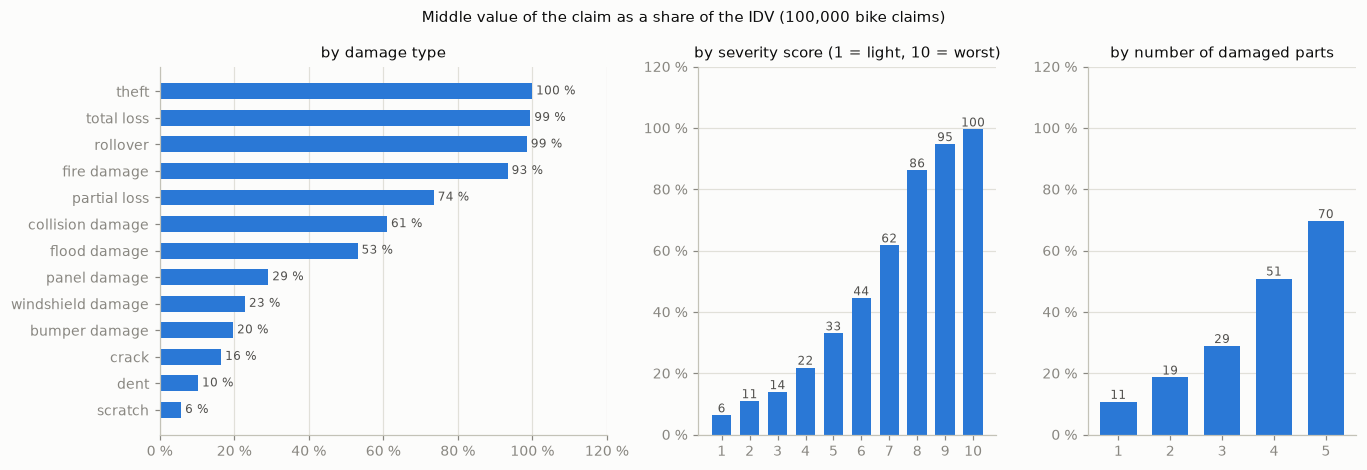

The damage type sets the level: theft, total loss, rollover cost about all of the IDV (the middle claim is 99 % or more of it), while scratch costs 6 % and dent 10 %. A higher severity score and more damaged parts push the share up further: from 6 % at severity 1 to 100 % at severity 10, and from 11 % with 1 damaged part to 70 % with 5.

In [4]:
figure, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 0.9]})
by_type = (100 * data.groupby("damage_type")["share"].median()).sort_values()
medians = {}
axes[0].barh(by_type.index, by_type.values, color=BLUE, height=0.6)
for position, value in enumerate(by_type.values):
    axes[0].text(value, position, f" {value:.0f} %", va="center", fontsize=8, color=INK2)
axes[0].set_xlim(0, 120)
axes[0].xaxis.set_major_formatter(PERCENT)
axes[0].set_title("by damage type")
tidy(axes[0], "x")
for axis, column, title in ((axes[1], "damage_severity_score", "by severity score (1 = light, 10 = worst)"),
                            (axes[2], "num_parts_affected", "by number of damaged parts")):
    by_value = 100 * data.groupby(column)["share"].median()
    medians[column] = by_value
    axis.bar(by_value.index.astype(str), by_value.values, color=BLUE, width=0.7)
    for position, value in enumerate(by_value.values):
        axis.text(position, value, f"{value:.0f}", ha="center", va="bottom", fontsize=8, color=INK2)
    axis.set_ylim(0, 120)
    axis.yaxis.set_major_formatter(PERCENT)
    axis.set_title(title)
    tidy(axis, "y")
figure.suptitle(f"Middle value of the claim as a share of the IDV ({len(data):,} bike claims)", fontsize=10)
figure.tight_layout()
plt.show()
by_severity, by_parts = medians["damage_severity_score"], medians["num_parts_affected"]
all_of_it = [name for name in by_type.index[::-1] if by_type[name] >= 95]
display(Markdown(f"The damage type sets the level: {', '.join(all_of_it)} cost about all of the IDV (the middle claim is {by_type[all_of_it].min():.0f} % or more of it), "
                 f"while {by_type.index[0]} costs {by_type.iloc[0]:.0f} % and {by_type.index[1]} {by_type.iloc[1]:.0f} %. A higher severity score and more damaged parts push the share up "
                 f"further: from {by_severity.iloc[0]:.0f} % at severity {by_severity.index[0]} to {by_severity.iloc[-1]:.0f} % at severity {by_severity.index[-1]}, and from "
                 f"{by_parts.iloc[0]:.0f} % with {by_parts.index[0]} damaged part to {by_parts.iloc[-1]:.0f} % with {by_parts.index[-1]}."))

The second picture shows the claims themselves, coloured with the brief's three severity words (minor, moderate, major).

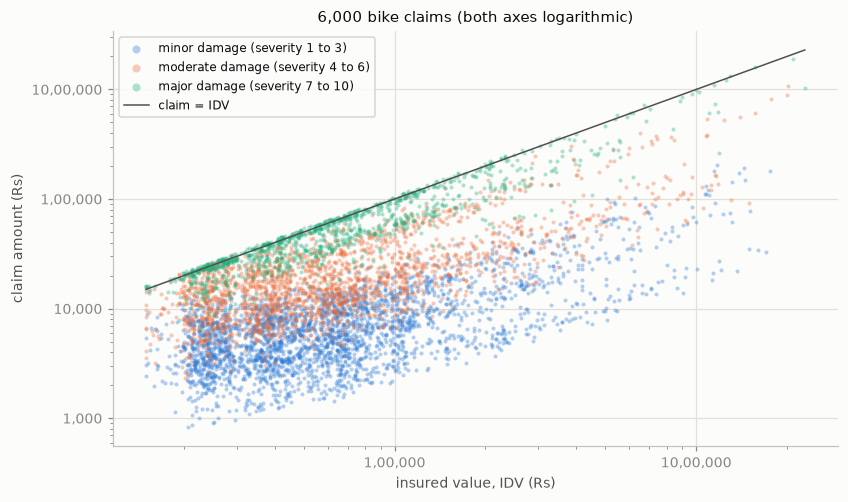

In [5]:
figure, axis = plt.subplots(figsize=(8.5, 4.9))
picked = data.sample(6000, random_state=0)
for (low, high, band), colour in zip(claims.SEVERITY_BANDS, (BLUE, ORANGE, AQUA)):
    part = picked[picked["damage_severity_score"].map(claims.severity_label) == band]
    axis.scatter(part["idv"], part["claim_amount"], s=7, alpha=0.35, color=colour, linewidths=0,
                 label=f"{band} damage (severity {low} to {high})")
limits = [picked["idv"].min(), picked["idv"].max()]
axis.plot(limits, limits, color=INK2, linewidth=1, label="claim = IDV")
axis.set(xscale="log", yscale="log", xlabel="insured value, IDV (Rs)", ylabel="claim amount (Rs)",
         title="6,000 bike claims (both axes logarithmic)")
axis.xaxis.set_major_formatter(RUPEES)
axis.yaxis.set_major_formatter(RUPEES)
axis.legend(loc="upper left", markerscale=2)
tidy(axis, "both")
plt.show()

Claims of the same kind of damage lie along lines that run parallel to the line "claim = IDV": the more the bike is worth, the
more the claim costs, in about the same proportion. That is why the model below learns the **share** of the IDV and not the
rupees (section 7 compares the two).

One more detail, the zero-depreciation add-on:

In [6]:
by_addon = 100 * data.groupby("zero_dep_addon")["share"].median()
display(by_addon.round(1).rename(index={0: "no zero-depreciation add-on", 1: "zero-depreciation add-on"}).to_frame("middle share of the IDV (%)"))
display(Markdown(f"With the add-on the middle claim is {by_addon[1]:.1f} % of the IDV, without it {by_addon[0]:.1f} %: a difference of "
                 f"{abs(by_addon[1] - by_addon[0]):.1f} points, {'higher' if by_addon[1] > by_addon[0] else 'lower'} with the add-on."))

,middle share of the IDV (%)
zero_dep_addon,
no zero-depreciation add-on,18.7
zero-depreciation add-on,20.1


With the add-on the middle claim is 20.1 % of the IDV, without it 18.7 %: a difference of 1.3 points, higher with the add-on.

## 3. Train / test split
80 % of the claims are used to learn, 20 % are held back and only used to measure the result (`random_state` 42, so everyone gets
the same split).

In [7]:
train, test = claims.split_data(data)
X_train, y_train = claims.xy(train, KIND, TASK)
X_test, y_test = claims.xy(test, KIND, TASK)
print(f"{len(train):,} claims to learn from, {len(test):,} claims held back for testing")
print("details the model gets:", ", ".join(X_train.columns))

80,000 claims to learn from, 20,000 claims held back for testing
details the model gets: damage_type, damage_severity_score, num_parts_affected, idv, zero_dep_addon


## 4. Feature engineering
The model cannot read words, so `ClaimFeatures` (in `acko/claims.py`) turns the details of a claim into numbers:

| From the claim | Becomes |
|---|---|
| damage type (a word) | a code number for each damage type, learned from the training claims |
| severity (1 to 10), damaged parts, IDV | passed on unchanged |
| zero-depreciation add-on | 0 or 1 (a skipped answer gets the more common one) |

`fit()` learns the code numbers and the typical answers from the **training claims only**. `transform()` then needs nothing but
the details of the claim itself. This is its code (the branch for `city_risk_score` is only used by the approval models):

In [8]:
print(textwrap.dedent(inspect.getsource(claims.ClaimFeatures.transform)))

def transform(self, X) -> pd.DataFrame:
    X = pd.DataFrame(X).copy()
    for column, value in self.defaults_.items():            # optional details the customer skipped
        X[column] = X[column].fillna(value) if column in X.columns else value
    out = pd.DataFrame(index=X.index)
    for name in feature_names(self.kind, self.task):
        if name == "city_risk_score":      # no city given (or an unknown one) -> the typical city risk
            known = X["city"].map(self.city_risk_) if "city" in X.columns else pd.Series(np.nan, index=X.index)
            out[name] = known.fillna(self.risk_default_).astype(float)
        elif name in self.codes_:
            out[name] = X[name].map(self.codes_[name]).astype(float)       # unknown word -> missing (NaN)
        else:
            out[name] = X[name].astype(float)
    return out



In [9]:
features = claims.ClaimFeatures(KIND, TASK).fit(X_train)
shown = X_test.head(5)
print("Five test claims, as the customer gives them:")
display(shown)
print("The same five, as the model sees them:")
display(features.transform(shown).round(2))
print("Code numbers learned for the damage types:")
print({word: int(number) for word, number in features.codes_["damage_type"].items()})
skipped = features.transform(shown.drop(columns=["zero_dep_addon"]))["zero_dep_addon"]
print("If the zero-depreciation answer is skipped it becomes", skipped.unique().tolist(), "(the more common answer in the training claims)")
assert skipped.nunique() == 1

Five test claims, as the customer gives them:


,damage_type,damage_severity_score,num_parts_affected,idv,zero_dep_addon
75721,dent,3,1,37753,0
80184,dent,2,2,25870,1
19864,collision damage,6,3,73315,1
76699,collision damage,7,3,120360,1
92991,bumper damage,5,4,36443,0


The same five, as the model sees them:


,damage_type,damage_severity_score,num_parts_affected,idv,zero_dep_addon
75721,3.0,3.0,1.0,37753.0,0.0
80184,3.0,2.0,2.0,25870.0,1.0
19864,1.0,6.0,3.0,73315.0,1.0
76699,1.0,7.0,3.0,120360.0,1.0
92991,0.0,5.0,4.0,36443.0,0.0


Code numbers learned for the damage types:
{'bumper damage': 0, 'collision damage': 1, 'crack': 2, 'dent': 3, 'fire damage': 4, 'flood damage': 5, 'panel damage': 6, 'partial loss': 7, 'rollover': 8, 'scratch': 9, 'theft': 10, 'total loss': 11, 'windshield damage': 12}
If the zero-depreciation answer is skipped it becomes [0.0] (the more common answer in the training claims)


## 5. Training
The model is a **gradient boosting** regressor (`HistGradientBoostingRegressor`): many small decision trees, each one correcting the
mistakes of the trees before it. Two choices matter:

- **It learns the share, not the rupees.** `ClaimAmountModel` learns log(amount / IDV) and multiplies its answer by the IDV
  again. One pattern ("a dent costs about a tenth of what the bike is worth") then applies to a bike of any IDV.
- **Damage type is a real category.** The trees may put "theft" and "total loss" on one side of a split without pretending that one
  damage type is "bigger" than another, which a plain code number would suggest.

Training stops by itself when 10 % of the training claims, kept aside inside the training data, show no more gain for 10 rounds in
a row (at most 1,000 rounds). This is the code of `fit()`:

In [10]:
print(textwrap.dedent(inspect.getsource(claims.ClaimAmountModel.fit)))

def fit(self, X, y):
    X = pd.DataFrame(X)
    idv = X["idv"].to_numpy(dtype=float)
    self.features_ = ClaimFeatures(self.kind, "amount").fit(X)
    self.booster_ = HistGradientBoostingRegressor(
        max_iter=MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0,
        categorical_features=categorical_positions(self.kind, "amount"))
    self.booster_.fit(self.features_.transform(X), np.log(np.asarray(y, dtype=float) / idv))
    self.n_rounds_ = int(self.booster_.n_iter_)
    return self



In [11]:
started = time.time()
model = claims.build_model(KIND, TASK).fit(X_train, y_train)
print(f"trained in {time.time() - started:.1f} s, {model.n_rounds_} boosting rounds")

trained in 0.4 s, 72 boosting rounds


## 6. Results against the targets
All numbers below are measured on the held-back test claims, which the model never saw while learning.

In [12]:
metrics = claims.evaluate_amount(model, KIND, X_test, y_test)
score = metrics["all"]
display(pd.DataFrame(
    [["R2", f"{score['r2']:.4f}", "share of the ups and downs of the claim that the model explains (1 = all of it)"],
     ["RMSE", inr(score["rmse"]), "typical size of a mistake in rupees; the biggest claims weigh most"],
     ["MAE", inr(score["mae"]), "average mistake in rupees"],
     ["average claim", inr(score["mean_claim"]), "to compare the mistakes with"],
     ["typical error", f"{score['median_pct_error']:.1f} %", "half of the estimates are closer than this to the real claim"],
     ["within 10 %", f"{score['within_10']:.0f} %", "share of the estimates less than 10 % away from the real claim"],
     ["within 25 %", f"{score['within_25']:.0f} %", "share of the estimates less than 25 % away from the real claim"]],
    columns=["measure", f"{score['n']:,} test claims", "what it says"]).set_index("measure"))
met = score["r2"] > claims.TARGET_R2 and score["median_pct_error"] < claims.TARGET_MEDIAN_ERROR
print(f"targets: R2 above {claims.TARGET_R2} and typical error below {claims.TARGET_MEDIAN_ERROR:g} %   ->   "
      f"R2 {score['r2']:.4f}, typical error {score['median_pct_error']:.1f} %   ->   {'MET' if met else 'NOT MET'}")
assert met, "The model misses the targets"

,"20,000 test claims",what it says
measure,,
R2,0.9959,share of the ups and downs of the claim that t...
RMSE,"₹4,613",typical size of a mistake in rupees; the bigge...
MAE,"₹2,338",average mistake in rupees
average claim,"₹29,723",to compare the mistakes with
typical error,10.8 %,half of the estimates are closer than this to ...
within 10 %,47 %,share of the estimates less than 10 % away fro...
within 25 %,79 %,share of the estimates less than 25 % away fro...


targets: R2 above 0.85 and typical error below 15 %   ->   R2 0.9959, typical error 10.8 %   ->   MET


The same numbers for claims of different insured value (IDV), and for each damage type:

In [13]:
display(pd.DataFrame([{"IDV": b["label"], "test claims": f"{b['n']:,}", "R2": round(b["r2"], 4), "RMSE": inr(b["rmse"]),
                       "typical error": f"{b['median_pct_error']:.1f} %"} for b in metrics["bands"]]).set_index("IDV"))
predicted = np.asarray(model.predict(X_test), dtype=float)
actual = y_test.to_numpy(dtype=float)
errors = pd.DataFrame({"damage type": X_test["damage_type"].to_numpy(), "gap": np.abs(predicted / actual - 1)})
by_type = errors.groupby("damage type")["gap"].agg(["size", "median"])
by_type["median"] = (100 * by_type["median"]).round(1)
display(by_type.rename(columns={"size": "test claims", "median": "typical error (%)"}).sort_values("typical error (%)"))
band_errors = [b["median_pct_error"] for b in metrics["bands"]]
worst = by_type["median"].idxmax()
display(Markdown(f"The typical error is **{band_errors[0]:.1f} %** in the cheapest IDV band and **{band_errors[-1]:.1f} %** in the dearest one, and the largest "
                 f"of the damage types is **{by_type.loc[worst, 'median']:.1f} %** for {worst}. Small claims have the larger errors in percent: the same rupee "
                 "mistake weighs more on a small claim."))
weak = [f"{b['label']} ({b['median_pct_error']:.1f} %)" for b in metrics["bands"] if b["median_pct_error"] >= claims.TARGET_MEDIAN_ERROR]
weak += [f"{name} ({by_type.loc[name, 'median']:.1f} %)" for name in by_type.index if by_type.loc[name, "median"] >= claims.TARGET_MEDIAN_ERROR]
if weak:
    display(Markdown(f"**Read this honestly:** the target (a typical error below {claims.TARGET_MEDIAN_ERROR:g} %) is met for all claims together, but not inside every group. "
                     f"The typical error is {claims.TARGET_MEDIAN_ERROR:g} % or more for: {', '.join(weak)}."))

,test claims,R2,RMSE,typical error
IDV,,,,
"up to 50,000","8,913",0.9472,"₹2,396",16.1 %
"50,000 to 1 lakh","5,864",0.9822,"₹2,798",10.8 %
1 to 2 lakh,"2,850",0.9913,"₹3,518",7.9 %
above 2 lakh,"2,373",0.9961,"₹11,116",5.0 %


,test claims,typical error (%)
damage type,,
rollover,401,3.9
theft,834,4.1
total loss,180,4.1
fire damage,408,4.2
partial loss,206,6.3
collision damage,2449,6.7
flood damage,791,7.3
windshield damage,806,10.3
panel damage,1243,10.5


The typical error is **16.1 %** in the cheapest IDV band and **5.0 %** in the dearest one, and the largest of the damage types is **22.8 %** for scratch. Small claims have the larger errors in percent: the same rupee mistake weighs more on a small claim.

**Read this honestly:** the target (a typical error below 15 %) is met for all claims together, but not inside every group. The typical error is 15 % or more for: up to 50,000 (16.1 %), scratch (22.8 %).

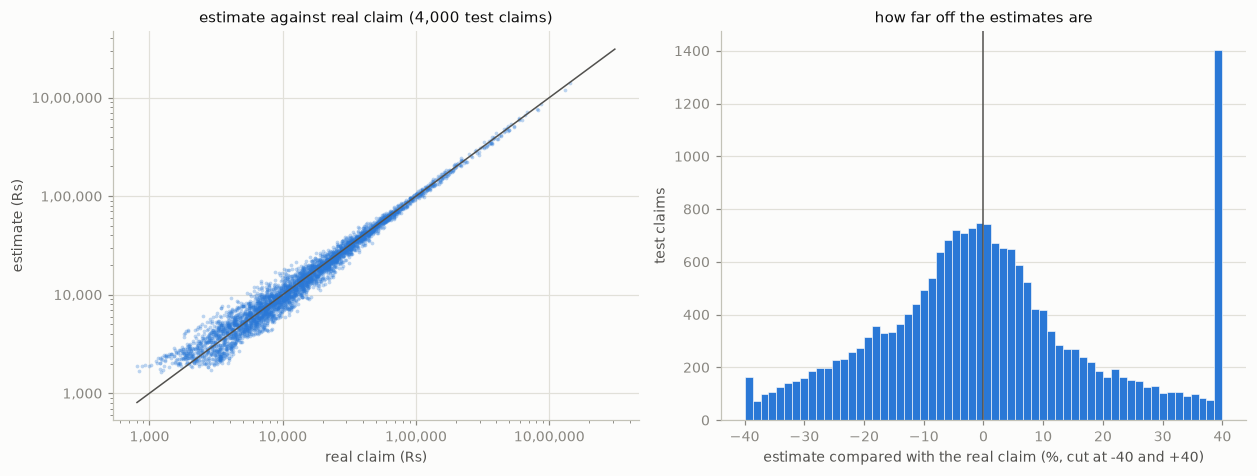

middle of the signed gaps: -0.68 %   (0 would mean no leaning towards too high or too low)


In [14]:
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
picked = np.random.default_rng(0).choice(len(actual), size=4000, replace=False)
axes[0].scatter(actual[picked], predicted[picked], s=6, alpha=0.3, color=BLUE, linewidths=0)
both = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axes[0].plot(both, both, color=INK2, linewidth=1)
axes[0].set(xscale="log", yscale="log", xlabel="real claim (Rs)", ylabel="estimate (Rs)", title="estimate against real claim (4,000 test claims)")
axes[0].xaxis.set_major_formatter(RUPEES)
axes[0].yaxis.set_major_formatter(RUPEES)
tidy(axes[0], "both")
signed = 100 * (predicted / actual - 1)
axes[1].hist(np.clip(signed, -40, 40), bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
axes[1].axvline(0, color=INK2, linewidth=1)
axes[1].set(xlabel="estimate compared with the real claim (%, cut at -40 and +40)", ylabel="test claims", title="how far off the estimates are")
tidy(axes[1], "y")
figure.tight_layout()
plt.show()
print(f"middle of the signed gaps: {np.median(signed):+.2f} %   (0 would mean no leaning towards too high or too low)")

## 7. Why gradient boosting, and why it learns a share of the IDV
The same test claims, estimated four ways. The first three are simple on purpose; the fourth is the same kind of model as ours,
but it learns the rupees directly instead of the share of the IDV.

In [15]:
rows = claims.amount_baselines(KIND, X_train, y_train, X_test, y_test, model)
code_numbers = model.features_.transform(X_train)
rupee_model = HistGradientBoostingRegressor(max_iter=claims.MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0,
                                            categorical_features=claims.categorical_positions(KIND, TASK))
rupee_model.fit(code_numbers, y_train)
direct = claims.score_amount(y_test, rupee_model.predict(model.features_.transform(X_test)))
rows.insert(2, {"name": "Gradient boosting that learns rupees directly", **direct})
display(pd.DataFrame([{"method": r["name"], "R2": round(r["r2"], 4), "RMSE": inr(r["rmse"]), "typical error": f"{r['median_pct_error']:.1f} %",
                       "within 10 %": f"{r['within_10']:.0f} %"} for r in rows]).set_index("method"))
linear = rows[1]
assert score["rmse"] < direct["rmse"] and score["median_pct_error"] < direct["median_pct_error"], "The text below says that learning the share is better; check it."
display(Markdown(f"Learning the share instead of the rupees lowers the RMSE from {inr(direct['rmse'])} to {inr(score['rmse'])} and the typical "
                 f"error from {direct['median_pct_error']:.1f} % to {score['median_pct_error']:.1f} %. Straight-line rules (linear regression) end at a typical "
                 f"error of {linear['median_pct_error']:.1f} %: trees can let one detail matter differently for different damage types, a straight-line rule cannot."))

,R2,RMSE,typical error,within 10 %
method,,,,
Typical share of the IDV for everyone,0.3190,"₹59,133",66.5 %,7 %
Linear regression (straight-line rules),0.6455,"₹42,664",22.0 %,24 %
Gradient boosting that learns rupees directly,0.9493,"₹16,141",11.9 %,45 %
Gradient boosting (this project's model),0.9959,"₹4,613",10.8 %,47 %


Learning the share instead of the rupees lowers the RMSE from ₹16,141 to ₹4,613 and the typical error from 11.9 % to 10.8 %. Straight-line rules (linear regression) end at a typical error of 22.0 %: trees can let one detail matter differently for different damage types, a straight-line rule cannot.

## 8. Would more columns help?
The claims file has more columns than the five the model uses (city, state, the make and model, the year, the premium paid, the day
of the week, and so on). Were they left out for a good reason? The test: give the same kind of model **every other column** of the
file, except the answers and the date, and measure it on the same test claims.

In [16]:
raw = pd.read_csv(claims.raw_path(KIND)).drop_duplicates("record_id").set_index("record_id")
used = set(claims.input_columns(KIND, TASK)) | set(claims.feature_names(KIND, TASK)) | set(claims.lookup_columns(TASK))
never = {"claim_amount", "claim_approved", "approval_probability", "affected_parts", "incident_date"}       # answers, a hidden score, a list of words, a date
extra = [column for column in raw.columns if column not in used | never]
words = [column for column in extra if not pd.api.types.is_numeric_dtype(raw[column])]
print(f"{len(extra)} more columns ({len(words)} of them hold words): {', '.join(extra)}")

23 more columns (10 of them hold words): customer_age, city, state, city_tier, city_risk_score, vehicle_make, vehicle_model, segment, engine_cc, manufacturing_year, vehicle_age_years, policy_type, policy_age_months, annual_premium_paid, previous_claims_count, ncb_at_claim_percent, usage_type, rider_experience_years, helmet_worn, incident_day_of_week, incident_month, incident_time_of_day, incident_type


In [17]:
more_train = raw.loc[train["record_id"], extra].reset_index(drop=True)
more_test = raw.loc[test["record_id"], extra].reset_index(drop=True)
for column in words:                                    # words -> code numbers, learned from the training claims only
    codes = {word: number for number, word in enumerate(sorted(more_train[column].dropna().unique()))}
    more_train[column] = more_train[column].map(codes).astype(float)
    more_test[column] = more_test[column].map(codes).astype(float)
learn = pd.concat([model.features_.transform(X_train).reset_index(drop=True), more_train.astype(float)], axis=1)
check = pd.concat([model.features_.transform(X_test).reset_index(drop=True), more_test.astype(float)], axis=1)
is_category = [column in claims.CATEGORY_COLUMNS or column in words for column in learn.columns]
wide = HistGradientBoostingRegressor(max_iter=claims.MAX_ROUNDS, learning_rate=0.1, early_stopping=True, random_state=0,
                                     categorical_features=is_category)
wide.fit(learn, np.log(y_train.to_numpy(dtype=float) / X_train["idv"].to_numpy(dtype=float)))
wide_score = claims.score_amount(y_test, np.exp(wide.predict(check)) * X_test["idv"].to_numpy(dtype=float))
display(pd.DataFrame(
    [{"model": f"the {len(X_train.columns)} details we use", "R2": round(score["r2"], 4), "RMSE": inr(score["rmse"]), "typical error": f"{score['median_pct_error']:.1f} %"},
     {"model": f"the same plus {len(extra)} more columns", "R2": round(wide_score["r2"], 4), "RMSE": inr(wide_score["rmse"]),
      "typical error": f"{wide_score['median_pct_error']:.1f} %"}]).set_index("model"))

,R2,RMSE,typical error
model,,,
the 5 details we use,0.9959,"₹4,613",10.8 %
the same plus 23 more columns,0.9949,"₹5,117",11.0 %


In [18]:
assert wide_score["median_pct_error"] > score["median_pct_error"] - 0.5, "The text below says that the extra columns do not help; check it."
display(Markdown(f"With {len(extra)} more columns the typical error is {wide_score['median_pct_error']:.1f} % (with the five details: {score['median_pct_error']:.1f} %) and the RMSE "
                 f"{inr(wide_score['rmse'])} (with the five details: {inr(score['rmse'])}). The extra columns do not make the estimates better, so this test finds nothing "
                 "in them that explains the part of the claim the five details leave open. Keeping the model to five details also keeps the claim page short: "
                 "a customer is asked only for what matters."))

With 23 more columns the typical error is 11.0 % (with the five details: 10.8 %) and the RMSE ₹5,117 (with the five details: ₹4,613). The extra columns do not make the estimates better, so this test finds nothing in them that explains the part of the claim the five details leave open. Keeping the model to five details also keeps the claim page short: a customer is asked only for what matters.

## 9. SHAP: why does the model give this amount?
SHAP answers: "for this claim, how much did each detail push the estimate up or down?" It starts from a **typical claim** and gives
every detail its share of the difference, so that

    typical claim + the push of every detail = the model's estimate, exactly.

Two choices, both explained in `acko/claims_explain.py`:

- The answer that is explained is the claim as a **share of the IDV**. Multiplied by the IDV of a claim, the pushes are rupees.
- SHAP's fast `TreeExplainer` is **not** used. These trees split on categories (the damage type), and for such splits its pieces do
  not add up to the model's answer; the check below shows by how much. SHAP's `Permutation` explainer only asks the model
  questions, so it is exact for any model. It is slower, which is why 300 test claims are explained, not all of them.

In [19]:
background = explain.background_claims(model, TASK, X_train)          # 100 training claims that stand for a typical claim
sample = X_test.sample(explain.N_EXPLAINED, random_state=0)           # 300 test claims to explain
result = explain.explain(model, TASK, background, sample)
add_gap = explain.additivity_gap(result)
print(f"SHAP values for {len(sample)} test claims, computed in {result.seconds:.0f} s")
print(f"typical share of the IDV: {100 * result.base:.1f} %;   largest gap between 'typical + pushes' and the model's own answer: {add_gap:.1e}")
assert add_gap < 1e-9, "the pieces must add up to the model's answer"

SHAP values for 300 test claims, computed in 28 s
typical share of the IDV: 32.3 %;   largest gap between 'typical + pushes' and the model's own answer: 2.9e-15


In [20]:
# For comparison: SHAP's fast TreeExplainer on the same claims. It runs without an error, but its pieces do not add up.
try:
    tree = shap.TreeExplainer(model.booster_)
    tree_pieces = np.asarray(tree.shap_values(result.table))
    tree_gap = float(np.abs(np.ravel(tree.expected_value)[0] + tree_pieces.sum(axis=1) - model.booster_.predict(result.table)).max())
    print(f"TreeExplainer: largest gap between 'typical + pieces' and the model's own answer: {tree_gap:.1f} on the model's log scale "
          f"(the Permutation explainer above: {add_gap:.0e})")
except Exception as problem:
    print("TreeExplainer could not be used on this model:", type(problem).__name__)

TreeExplainer: largest gap between 'typical + pieces' and the model's own answer: 3.0 on the model's log scale (the Permutation explainer above: 3e-15)


**Which details matter most.** The bars show how far each detail moves the estimate on average, in points of the IDV (10 points =
10 % of the insured value). The picture is saved in `reports/shap/`.

saved: reports/shap/claims_bike_amount_importance.png


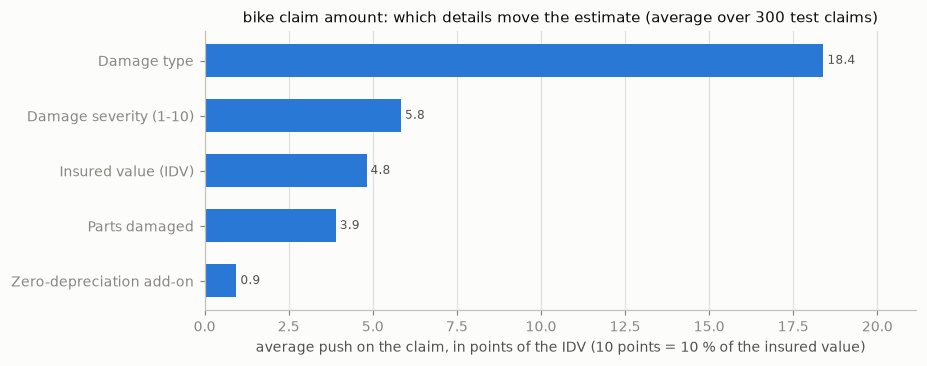

In [21]:
figure, axis = plt.subplots(figsize=(8.5, 3.4))
explain.draw_importance(axis, result, "average push on the claim, in points of the IDV (10 points = 10 % of the insured value)")
axis.set_title(f"bike claim amount: which details move the estimate (average over {len(sample)} test claims)")
figure.tight_layout()
print("saved: reports/shap/" + explain.save_figure(figure, f"claims_{KIND}_{TASK}_importance.png").name)
plt.show()

**Every test claim as a dot.** Left of the middle line the detail pulls the estimate down, right of it pushes it up. The colour is
the value of the detail: red = high, blue = low. For the damage type, "high" means a dearer type of damage: the types are coloured
in the order of how much of the IDV they cost, from the cheapest to the dearest (`claims_explain.colour_codes`).

saved: reports/shap/claims_bike_amount_summary.png


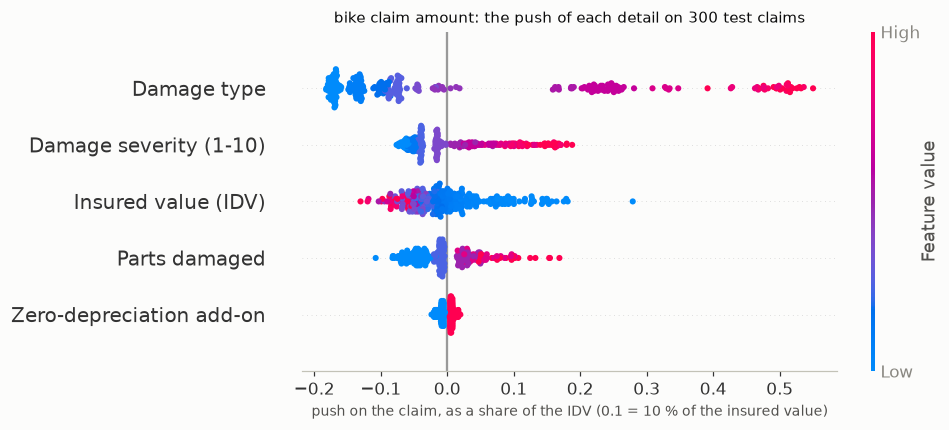

In [22]:
damage_order = list(data.groupby("damage_type")["share"].median().sort_values().index)        # cheapest damage type first
shap.summary_plot(result.values, explain.colour_codes(model, result.table, damage_order), feature_names=result.labels, show=False,
                  max_display=len(result.names), plot_size=(9, 3.9))
plt.xlabel("push on the claim, as a share of the IDV (0.1 = 10 % of the insured value)", fontsize=9)
plt.title(f"bike claim amount: the push of each detail on {len(sample)} test claims", fontsize=10)
print("saved: reports/shap/" + explain.save_figure(plt.gcf(), f"claims_{KIND}_{TASK}_summary.png").name)
plt.show()

**One claim, step by step.** The claim below is the one whose estimate is closest to the middle estimate of the 300. The grey bar on
the left is a typical claim for the same IDV; each coloured bar is what one detail adds (blue) or takes off (orange), from the
biggest push to the smallest; the grey bar on the right is the model's estimate.

In [23]:
rupees = result.output * sample["idv"].to_numpy(dtype=float)           # the model's estimate for each explained claim
position = int(np.argmin(np.abs(rupees - np.median(rupees))))
row = sample.iloc[position]
steps, start, end = explain.example_steps(result, position, row)
display(pd.DataFrame([{"detail": label, "this claim": detail, "push on the claim": ("+" if value >= 0 else "-") + inr(abs(value))}
                      for label, detail, value in steps]).set_index("detail"))
own_estimate = float(model.predict(sample.iloc[[position]])[0])
print(f"typical claim for this IDV {inr(start)}  +  the pushes  =  {inr(end)}   (the model's own estimate: {inr(own_estimate)})")
assert abs(start + sum(value for _, _, value in steps) - end) < 0.01
assert abs(end - own_estimate) < 0.01

,this claim,push on the claim
detail,,
Damage type,scratch,"-₹50,599"
Insured value (IDV),"₹2,88,394","-₹25,121"
Damage severity (1-10),3 of 10,"-₹10,987"
Parts damaged,3,"+₹4,887"
Zero-depreciation add-on,yes,"+₹1,224"


typical claim for this IDV ₹93,184  +  the pushes  =  ₹12,588   (the model's own estimate: ₹12,588)


saved: reports/shap/claims_bike_amount_example.png


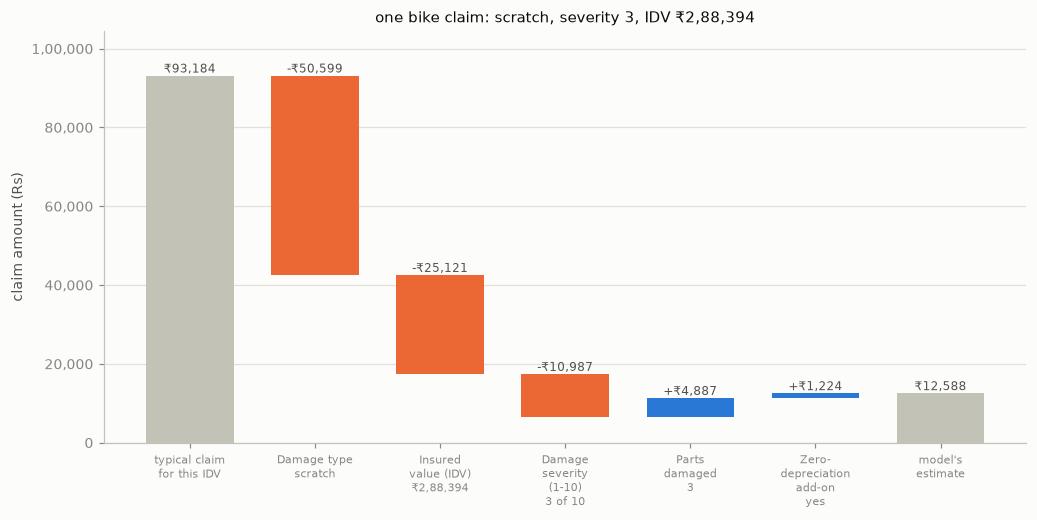

In [24]:
figure, axis = plt.subplots(figsize=(9.5, 4.8))
explain.draw_waterfall(axis, steps, start, end, "typical claim\nfor this IDV", "model's\nestimate", money=True)
axis.set_title(f"one bike claim: {row['damage_type']}, severity {int(row['damage_severity_score'])}, IDV {inr(row['idv'])}")
axis.set_ylabel("claim amount (Rs)")
figure.tight_layout()
print("saved: reports/shap/" + explain.save_figure(figure, f"claims_{KIND}_{TASK}_example.png").name)
plt.show()

## 10. Checking the saved `.pkl` file
The claim page does not train anything: it loads `models/claim_bike_amount.pkl`. This step opens that file and checks that it
gives the same answers as the model trained above, and that it meets the targets on its own.

In [25]:
try:
    bundle = claims.load_bundle(KIND, TASK)
except claims.ModelMissing as problem:
    bundle = None
    print(problem)
if bundle is not None:
    saved = bundle["model"]
    path = claims.MODEL_FILES[(KIND, TASK)]
    saved_metrics = claims.evaluate_amount(saved, KIND, X_test, y_test)["all"]
    difference = float(np.abs(np.asarray(saved.predict(X_test), dtype=float) - predicted).max())
    print(f"file: models/{path.name} ({path.stat().st_size / 1e6:.2f} MB), trained {bundle['trained_at']}, scikit-learn {bundle['versions']['scikit-learn']}")
    print(f"R2 of the saved model on the test claims: {saved_metrics['r2']:.4f}   (trained here: {score['r2']:.4f})")
    print(f"largest difference between the saved model and the one trained here: {inr(difference)}   (0 or a few paise: the same model)")
    assert saved_metrics["r2"] > claims.TARGET_R2 and saved_metrics["median_pct_error"] < claims.TARGET_MEDIAN_ERROR

file: models/claim_bike_amount.pkl (0.12 MB), trained 2026-11-14 16:43, scikit-learn 1.9.1
R2 of the saved model on the test claims: 0.9959   (trained here: 0.9959)
largest difference between the saved model and the one trained here: ₹0   (0 or a few paise: the same model)


And the way the claim page asks for an estimate: one claim in, an amount (never more than the IDV), an approval probability and a
status out. Details that are skipped get typical values.

In [26]:
if bundle is not None:
    engine = claims.ClaimEngine.load()
    estimate = engine.estimate("bike", "scratch", 2, 1, 80_000, zero_dep=0)
    print("bike, scratch, severity 2, 1 part, IDV Rs 80,000, no zero-depreciation add-on:")
    print(f"   estimated claim {inr(estimate.amount)}  ({estimate.severity} damage)   approval probability {100 * estimate.probability:.1f} %  ->  {estimate.status}")

bike, scratch, severity 2, 1 part, IDV Rs 80,000, no zero-depreciation add-on:
   estimated claim ₹3,100  (minor damage)   approval probability 100.0 %  ->  approved


## Summary and limits

In [27]:
facts = claims.approval_rule_check(KIND)
groups_note = f" Groups at or above the {claims.TARGET_MEDIAN_ERROR:g} % bar: {', '.join(weak)}." if weak else ""
display(Markdown(f"""
**Bike claim amount model**

| | |
|---|---|
| model | gradient boosting on the share of the IDV (`HistGradientBoostingRegressor`), {model.n_rounds_} rounds |
| test claims | {score['n']:,} |
| R2 | {score['r2']:.4f} (target: above {claims.TARGET_R2}) |
| RMSE | {inr(score['rmse'])} |
| typical error | {score['median_pct_error']:.1f} % (target: below {claims.TARGET_MEDIAN_ERROR:g} %) |
| targets | {'MET' if met else 'NOT MET'} |
| saved model | `models/claim_bike_amount.pkl` |
| SHAP pictures | `reports/shap/claims_bike_amount_importance.png`, `_summary.png`, `_example.png` |
| run time of this notebook | {(time.time() - STARTED) / 60:.1f} minutes |

**Limits you should know about**

- The data is synthetic. The model learns the rules of this dataset, not those of real Acko claims.
- The typical error of {score['median_pct_error']:.1f} % is what is left after the five details are used. None of the {len(extra)} other columns brought it down
  (section 8), so it looks like random variation in the data itself. The typical error grows as claims get smaller: {band_errors[0]:.1f} % in the IDV band
  "{metrics['bands'][0]['label']}" against {band_errors[-1]:.1f} % in "{metrics['bands'][-1]['label']}" (section 6).{groups_note}
- {facts['amount_above_idv']:.1f} % of the claims in the file are above the insured value. A claim is never paid above the IDV, so the claim page limits
  the estimate to the IDV and says so.
- The claim page takes three of the five details (damage type, severity, damaged parts) from the photo with Gemini. The model was trained on the
  dataset's own values, so a wrong reading of a photo gives a wrong estimate. The page shows what Gemini read and lets the customer correct it.
- The test claims were also used to look at other columns (section 8). A stricter project would keep a third set that is touched only once.
- SHAP explains how the model arrives at its estimate. It does not say why a real insurer would pay that amount.
"""))


**Bike claim amount model**

| | |
|---|---|
| model | gradient boosting on the share of the IDV (`HistGradientBoostingRegressor`), 72 rounds |
| test claims | 20,000 |
| R2 | 0.9959 (target: above 0.85) |
| RMSE | ₹4,613 |
| typical error | 10.8 % (target: below 15 %) |
| targets | MET |
| saved model | `models/claim_bike_amount.pkl` |
| SHAP pictures | `reports/shap/claims_bike_amount_importance.png`, `_summary.png`, `_example.png` |
| run time of this notebook | 0.6 minutes |

**Limits you should know about**

- The data is synthetic. The model learns the rules of this dataset, not those of real Acko claims.
- The typical error of 10.8 % is what is left after the five details are used. None of the 23 other columns brought it down
  (section 8), so it looks like random variation in the data itself. The typical error grows as claims get smaller: 16.1 % in the IDV band
  "up to 50,000" against 5.0 % in "above 2 lakh" (section 6). Groups at or above the 15 % bar: up to 50,000 (16.1 %), scratch (22.8 %).
- 4.4 % of the claims in the file are above the insured value. A claim is never paid above the IDV, so the claim page limits
  the estimate to the IDV and says so.
- The claim page takes three of the five details (damage type, severity, damaged parts) from the photo with Gemini. The model was trained on the
  dataset's own values, so a wrong reading of a photo gives a wrong estimate. The page shows what Gemini read and lets the customer correct it.
- The test claims were also used to look at other columns (section 8). A stricter project would keep a third set that is touched only once.
- SHAP explains how the model arrives at its estimate. It does not say why a real insurer would pay that amount.
